In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
call_folder = '../option_data/calls/combined/'
call_data = pd.read_csv(call_folder + 'combined_calls.csv')

put_folder = '../option_data/puts/combined/'
put_data = pd.read_csv(put_folder + 'combined_puts.csv')



In [72]:
unique_expiries = call_data['expiry'].sort_values().unique()

## Analysis of Liquidity

The following is the plot for the total number of call options traded across different expiry dates. 

The visualization highlights a substantial level of market activity, with over 1.1 million contracts traded in a single day. This significant volume is a strong indicator of high liquidity in the options market, suggesting active participation from a wide range of market participants.

Such liquidity typically enhances price discovery, narrows bid-ask spreads, and provides more efficient trade execution for both institutional and retail traders.

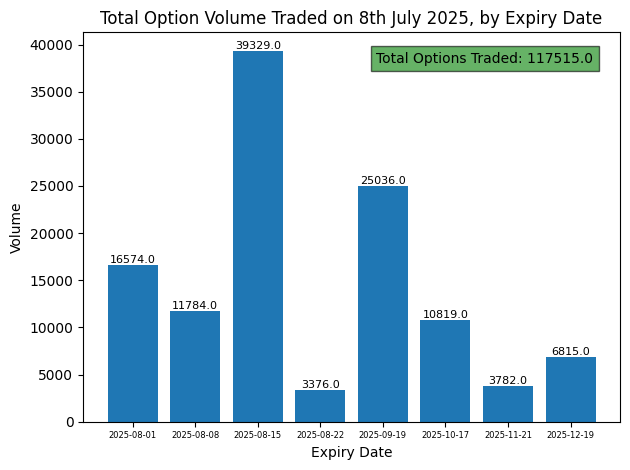

In [42]:
volume_by_expiry = call_data.groupby('expiry')['volume'].sum().reset_index()
total = sum(call_data['volume'])
plt.bar(volume_by_expiry['expiry'], volume_by_expiry['volume'])
plt.title('Total Option Volume Traded on 8th July 2025, by Expiry Date')
plt.xlabel('Expiry Date')
plt.xticks(fontsize=6)
plt.ylabel('Volume')

for i, volume in enumerate(volume_by_expiry['volume']):
    plt.text(i, volume, str(volume), ha='center', va='bottom', fontsize=8)

plt.text(0.95, 0.95, f'Total Options Traded: {total}', 
         ha='right', va='top', 
         transform=plt.gca().transAxes,
         fontsize=10, 
         bbox=dict(facecolor='green', alpha=0.6, edgecolor='black'))
plt.tight_layout()
plt.show()



Volume by Strike Prices, for the different expiry dates

Next is the visualisation for the total number of call options traded across various strike prices for each expiry date. 

The charts reveal a consistent pattern: strike prices in the range of K = 200 to K = 240 exhibit the highest trading volumes across nearly all expiries, indicating strong market interest around these levels—likely due to their proximity to the prevailing underlying price. (S = 210.10)

Notably, there are exceptions to this trend. For example, the call option expiring on 2025-08-08 saw an unusually high concentration of trading at K = 140, suggesting either a speculative position, a hedging strategy, or the unwinding of an earlier position. Such outliers may reflect differing expectations or risk management approaches among market participants.

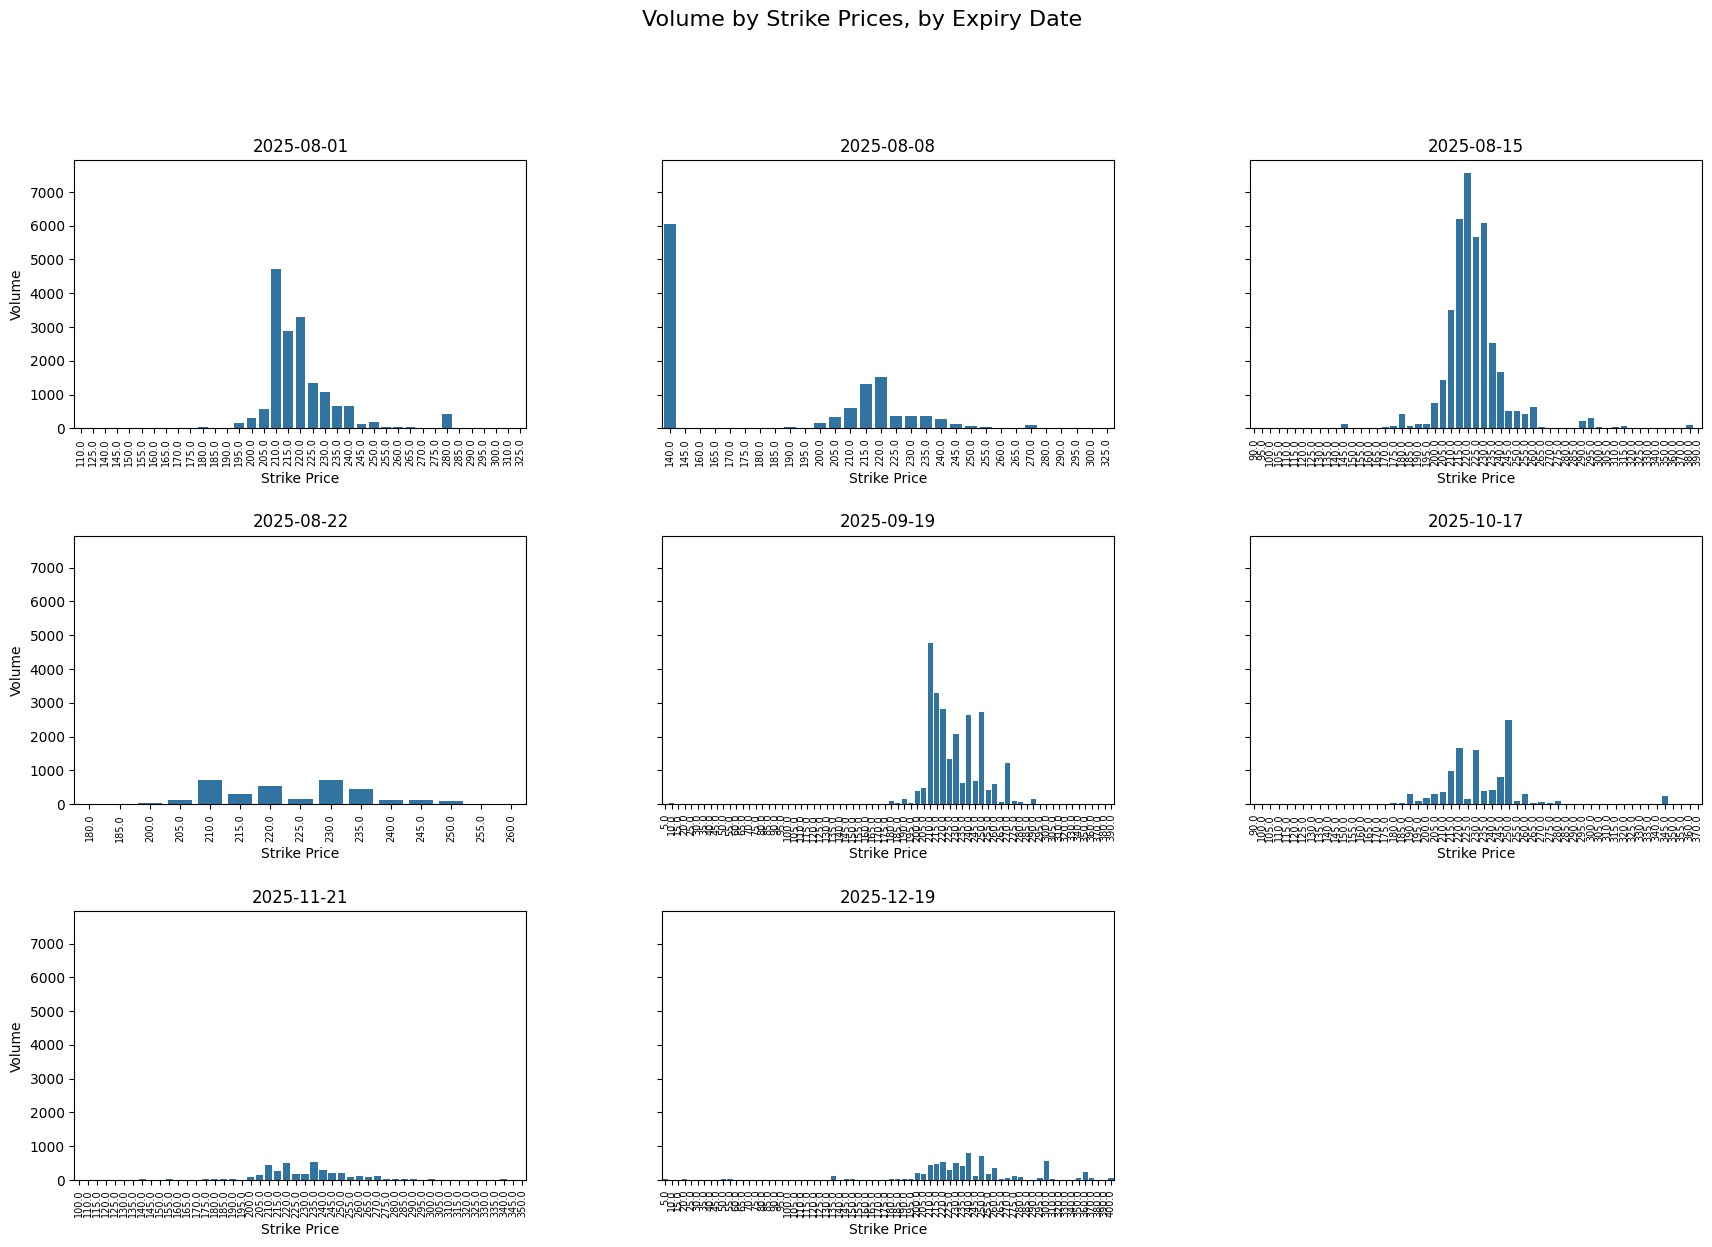

In [71]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

unique_expiries = call_data['expiry'].unique()
num_plots = len(unique_expiries)

cols = 3
rows = math.ceil(num_plots / cols)

fig, axes = plt.subplots(rows, cols, figsize=(cols*7, rows*5), sharey=True)
axes = axes.flatten()
fig.suptitle('Volume by Strike Prices, by Expiry Date', fontsize=16)
for i, expiry_date in enumerate(unique_expiries):
    subset = call_data[call_data['expiry'] == expiry_date]
    sns.barplot(data=subset, x='strike', y='volume', errorbar=None, ax=axes[i])
    axes[i].set_title(f'{expiry_date}')
    axes[i].tick_params(axis='x', rotation=90, labelsize=7)
    axes[i].set_xlabel('Strike Price')
    axes[i].set_ylabel('Volume')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.subplots_adjust(bottom=0.2, hspace=0.4, wspace=0.3)

plt.show()


Overall Volume by Strike Price

This visualization presents the aggregated trading volume of call options across all expiry dates, grouped by strike price. 

The resulting trend appears more consistent and aligns closely with the earlier observation — highlighting concentrated trading activity around specific strike levels.

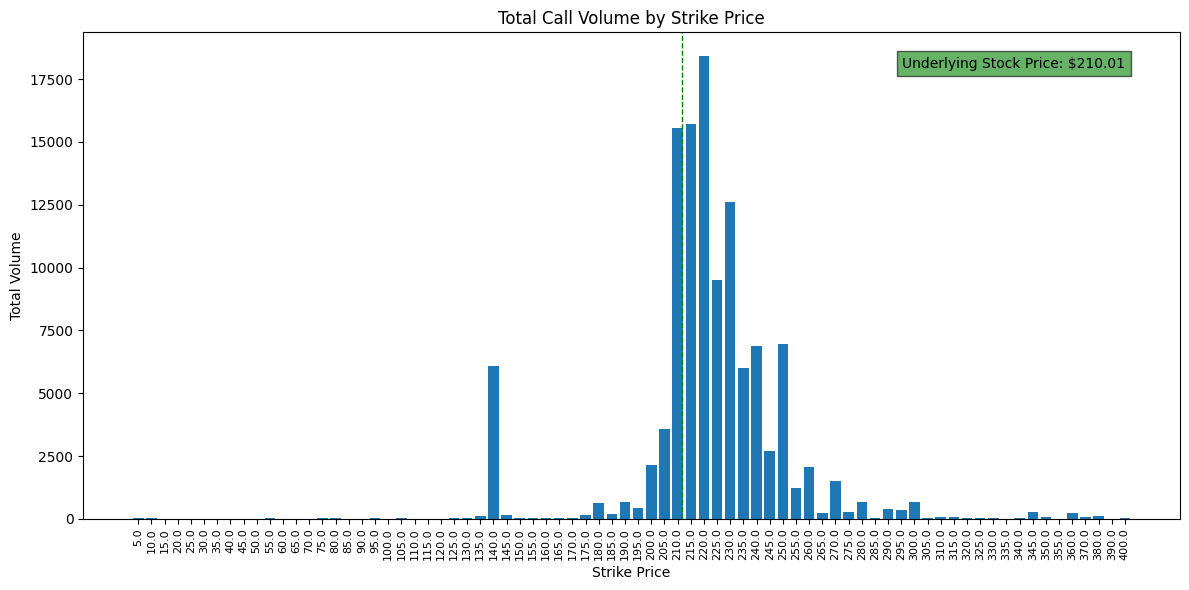

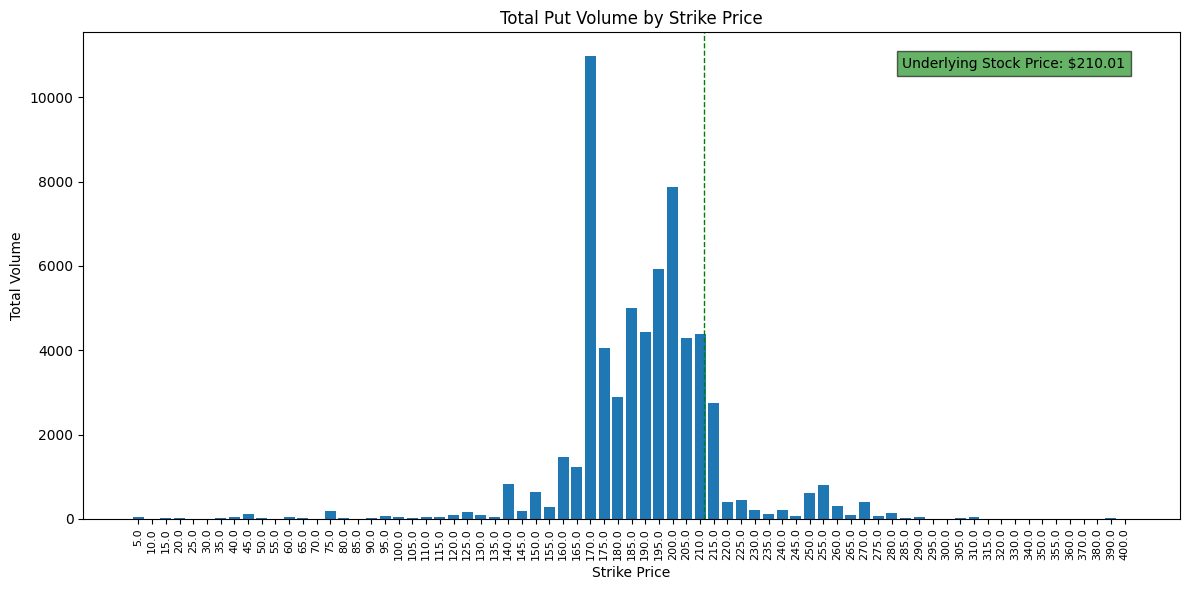

In [73]:
import matplotlib.pyplot as plt

call_volume_by_strike = call_data.groupby('strike')['volume'].sum().reset_index()
put_volume_by_strike = put_data.groupby('strike')['volume'].sum().reset_index()


plt.figure(figsize=(12, 6))
plt.bar(call_volume_by_strike['strike'].astype(str), call_volume_by_strike['volume'])
plt.title('Total Call Volume by Strike Price')
plt.xlabel('Strike Price')
plt.xticks(rotation=90, fontsize=8)  # Rotate labels for better readability
plt.ylabel('Total Volume')
plt.text(0.95, 0.95, 'Underlying Stock Price: $210.01', 
         ha='right', va='top', 
         transform=plt.gca().transAxes,
         fontsize=10, 
         bbox=dict(facecolor='green', alpha=0.6, edgecolor='black'))
plt.axvline(x=41.3, color='green', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()


plt.figure(figsize=(12, 6))
plt.bar(put_volume_by_strike['strike'].astype(str), put_volume_by_strike['volume'])
plt.title('Total Put Volume by Strike Price')
plt.xlabel('Strike Price')
plt.xticks(rotation=90, fontsize=8)  # Rotate labels for better readability
plt.ylabel('Total Volume')
plt.text(0.95, 0.95, 'Underlying Stock Price: $210.01', 
         ha='right', va='top', 
         transform=plt.gca().transAxes,
         fontsize=10, 
         bbox=dict(facecolor='green', alpha=0.6, edgecolor='black'))
plt.axvline(x=41.3, color='green', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()


## Bid-Ask Spread Analysis

The bid-ask spread represents the difference between the highest price a buyer is willing to pay (bid) and the lowest price a seller is willing to accept (ask). In the context of options trading, the bid-ask spread serves as a critical indicator of market liquidity, trading efficiency, and investor sentiment.

A narrow spread typically indicates a liquid and actively traded market, where there is a high level of agreement between buyers and sellers. This translates to lower transaction costs and easier entry and exit for traders. Conversely, a wider spread suggests lower liquidity, often seen in options with limited demand, far expiry dates, or strike prices that are deep in- or out-of-the-money.

The following plot visualises the distribution of the bid-ask spreads across all the call options traded

We can observe the following characteristics:

Tight Clustering Near Zero:
- The majority of options exhibit very narrow spreads (typically between $0.00 and $0.05), which is indicative of high liquidity and active trading. This is consistent with expectations for a highly liquid underlying asset such as AAPL, where tight spreads enable efficient trade execution.

Long Right Tail:
- A smaller subset of options displays wider spreads, extending up to $4.00. These are likely associated with:
    - Low trading volume or open interest
    - Deep in-the-money (ITM) or far out-of-the-money (OTM) strike prices
    - Contracts with long-dated expiries, where liquidity is naturally thinner
- This also accounts for the outliers we identified previously. 

Right-Skewed Distribution:
- Overall, the distribution is heavily right-skewed, with most options priced tightly around the mid-market. This skewness further reinforces the presence of an efficient and liquid market, where the vast majority of contracts are priced competitively.

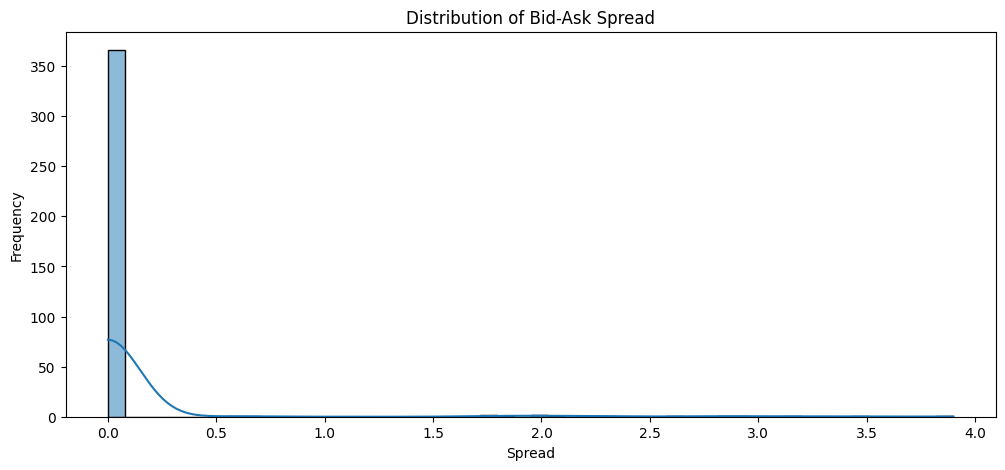

In [6]:
call_data['spread'] = call_data['ask'] - call_data['bid']
call_data['mid_price'] = (call_data['ask'] + call_data['bid']) / 2
call_data['relative_spread'] = call_data['spread'] / call_data['mid_price']

plt.figure(figsize=(12,5))
sns.histplot(call_data['spread'], bins=50, kde=True)
plt.title('Distribution of Bid-Ask Spread')
plt.xlabel('Spread')
plt.ylabel('Frequency')
plt.show()